# Project 01: E-Commerce Sales & Customer Behavior Analysis

## 1. Executive Summary & Setup
This notebook conducts an Exploratory Data Analysis (EDA) on the UCI Online Retail Dataset. The objective is to analyze sales performance, customer purchasing trends, product demand, and geographic distribution while delivering business recommendations.

### Importing the required libraries.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
print('Libraries loaded successfully.')

Libraries loaded successfully.


## 2. Data Loading & Initial Exploration
We load the dataset, check structural metadata, and inspect initial data statistics.

In [2]:
# Load dataset - Adjust filepath if using CSV or Excel format
try:
    df = pd.read_excel('Online Retail.xlsx')
except FileNotFoundError:
    df = pd.read_csv('Online Retail.csv', encoding='ISO-8859-1')

print(f'Dataset Shape: {df.shape}')
df.head()

Dataset Shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
# Check schema and missing values
print('--- Data Types & Non-Null Counts ---')
df.info()

print('\n--- Missing Value Count ---')
print(df.isnull().sum())

print('\n--- Missing Value Percentages ---')
print((df.isnull().sum() / len(df)) * 100)

--- Data Types & Non-Null Counts ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB

--- Missing Value Count ---
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

--- Missing Value Percentages ---
InvoiceNo       0.

## 3. Data Cleaning & Preprocessing
- Remove duplicate entries.
- Remove or impute missing CustomerID records.
- Identify and isolate cancelled transactions (prefixed with 'C' in InvoiceNo).
- Cast features into appropriate data types and create derived metrics (TotalPrice, YearMonth, Hour, DayOfWeek).

In [4]:
# Copy raw data
df_clean = df.copy()

# Remove exact duplicates
df_clean = df_clean.drop_duplicates()

# Filter out missing CustomerID for customer-centric analysis
df_clean = df_clean.dropna(subset=['CustomerID'])
df_clean['CustomerID'] = df_clean['CustomerID'].astype(int)

# Datetime conversion
df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'])

# Identify cancelled orders
df_clean['IsCancelled'] = df_clean['InvoiceNo'].astype(str).str.startswith('C')

# Feature engineering
df_clean['TotalPrice'] = df_clean['Quantity'] * df_clean['UnitPrice']
df_clean['YearMonth'] = df_clean['InvoiceDate'].dt.to_period('M')
df_clean['Hour'] = df_clean['InvoiceDate'].dt.hour
df_clean['DayOfWeek'] = df_clean['InvoiceDate'].dt.day_name()

# Filter positive transactions for general sales analysis
df_sales = df_clean[(df_clean['Quantity'] > 0) & (df_clean['UnitPrice'] > 0) & (~df_clean['IsCancelled'])]

print(f'Original rows: {len(df)}')
print(f'Cleaned sales dataset rows: {len(df_sales)}')

Original rows: 541909
Cleaned sales dataset rows: 392692


## 4. Visualizations & Exploratory Analysis

### A. 3 Histograms

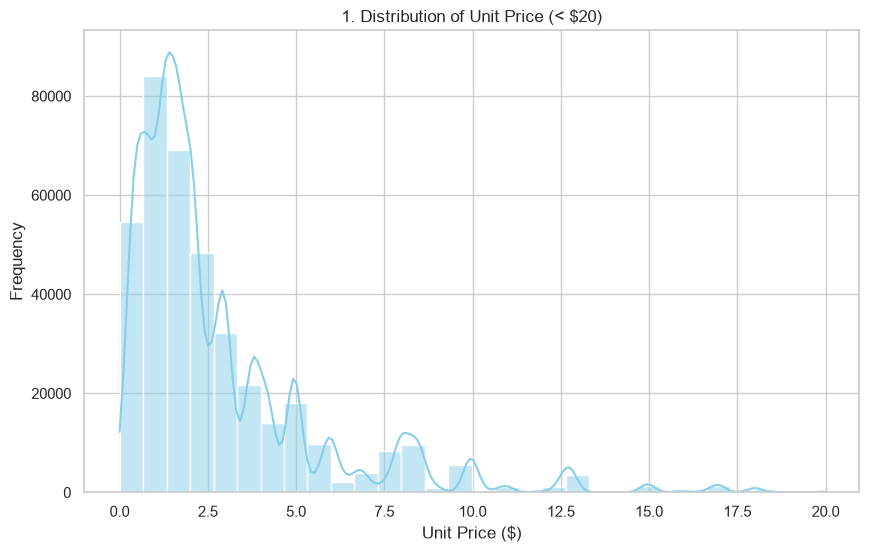

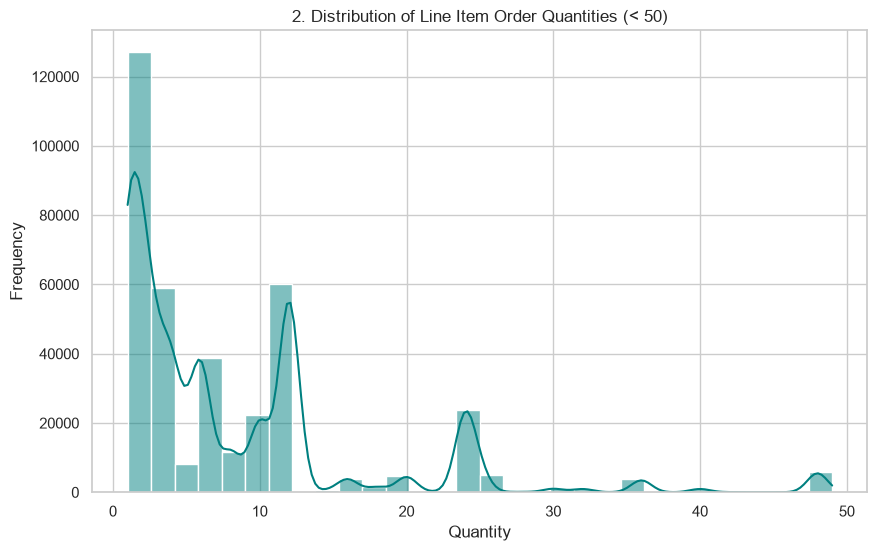

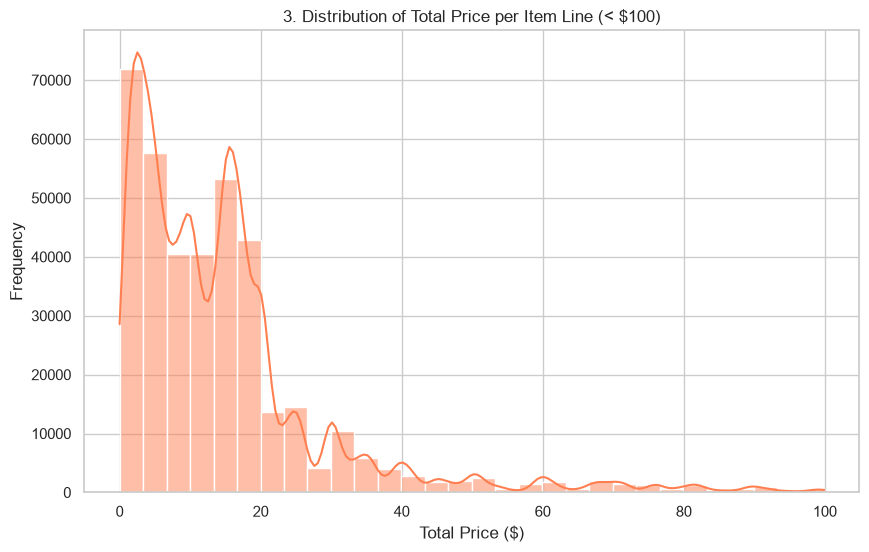

In [5]:
# 1. Histogram of Unit Price (< $20)
plt.figure()
sns.histplot(df_sales[df_sales['UnitPrice'] < 20]['UnitPrice'], bins=30, kde=True, color='skyblue')
plt.title('1. Distribution of Unit Price (< $20)')
plt.xlabel('Unit Price ($)')
plt.ylabel('Frequency')
plt.show()

# 2. Histogram of Order Quantity (< 50 items)
plt.figure()
sns.histplot(df_sales[df_sales['Quantity'] < 50]['Quantity'], bins=30, kde=True, color='teal')
plt.title('2. Distribution of Line Item Order Quantities (< 50)')
plt.xlabel('Quantity')
plt.ylabel('Frequency')
plt.show()

# 3. Histogram of Total Spend per Transaction Line Item (< $100)
plt.figure()
sns.histplot(df_sales[df_sales['TotalPrice'] < 100]['TotalPrice'], bins=30, kde=True, color='coral')
plt.title('3. Distribution of Total Price per Item Line (< $100)')
plt.xlabel('Total Price ($)')
plt.ylabel('Frequency')
plt.show()

### B. 3 Box Plots 

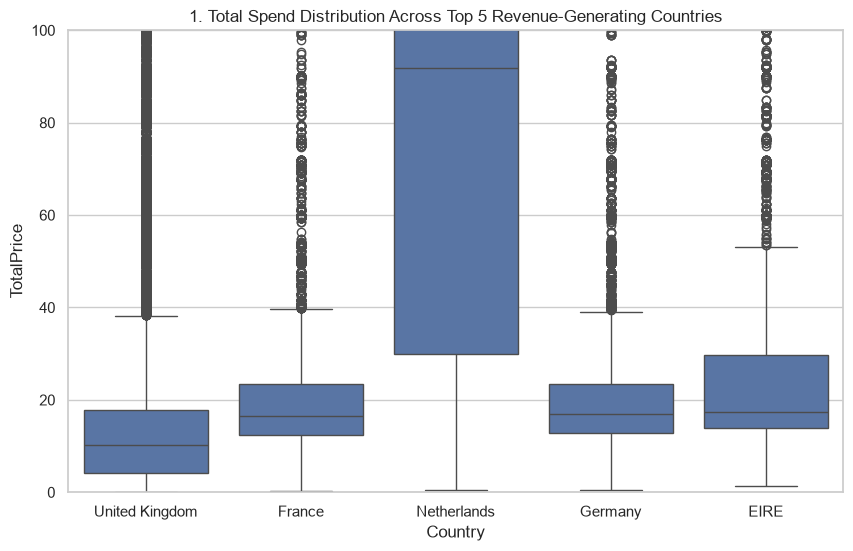

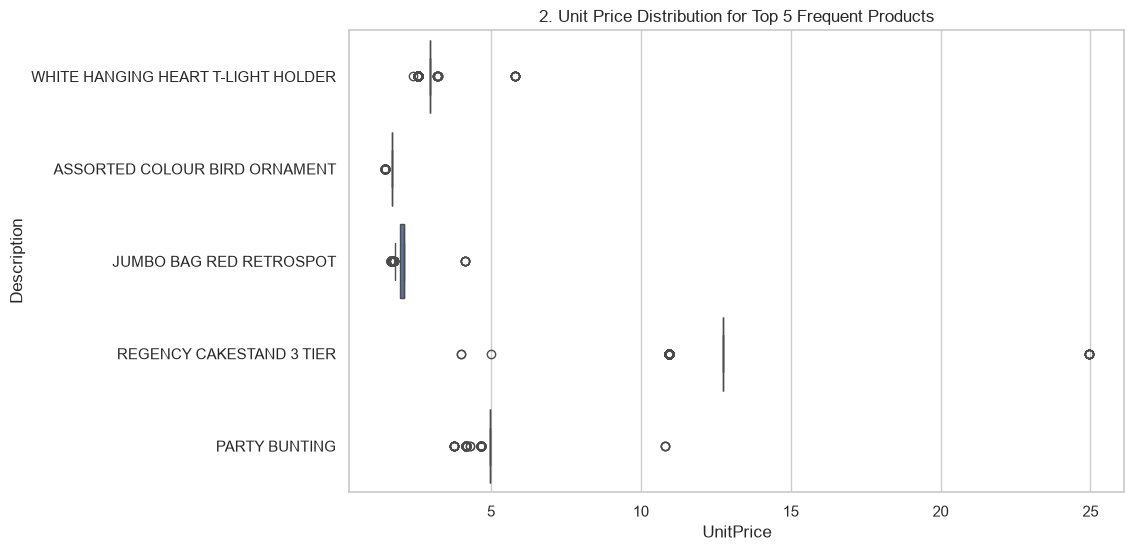

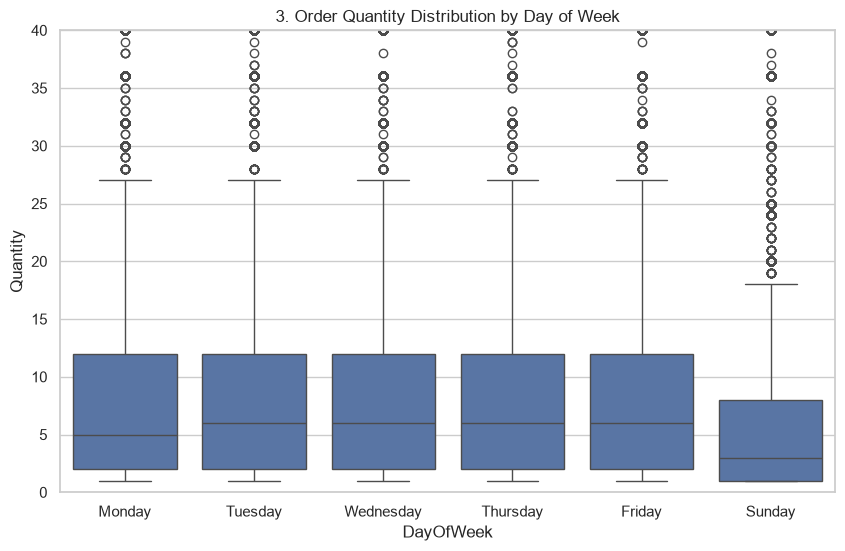

In [6]:
# 1. Box plot of Total Price across Top 5 Countries
top5_countries = df_sales.groupby('Country')['TotalPrice'].sum().nlargest(5).index
plt.figure()
sns.boxplot(data=df_sales[df_sales['Country'].isin(top5_countries)], x='Country', y='TotalPrice')
plt.ylim(0, 100)
plt.title('1. Total Spend Distribution Across Top 5 Revenue-Generating Countries')
plt.show()

# 2. Box plot of Unit Price across Top 5 Items
top5_items = df_sales['Description'].value_counts().nlargest(5).index
plt.figure()
sns.boxplot(data=df_sales[df_sales['Description'].isin(top5_items)], x='UnitPrice', y='Description')
plt.title('2. Unit Price Distribution for Top 5 Frequent Products')
plt.show()

# 3. Box plot of Quantity by Day of Week
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Sunday']
plt.figure()
sns.boxplot(data=df_sales, x='DayOfWeek', y='Quantity', order=days_order)
plt.ylim(0, 40)
plt.title('3. Order Quantity Distribution by Day of Week')
plt.show()

### C. 3 Bar Charts 

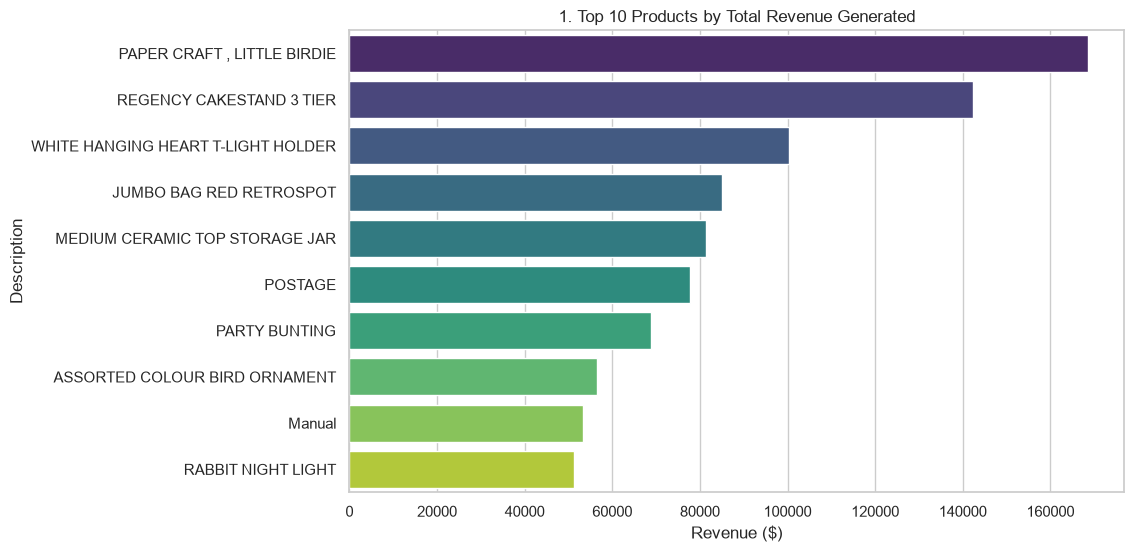

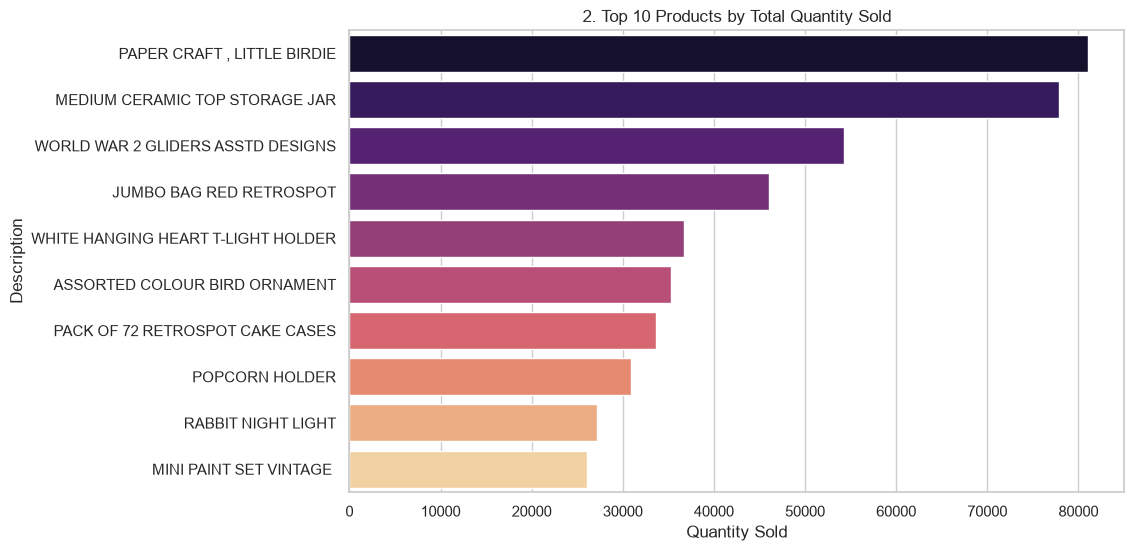

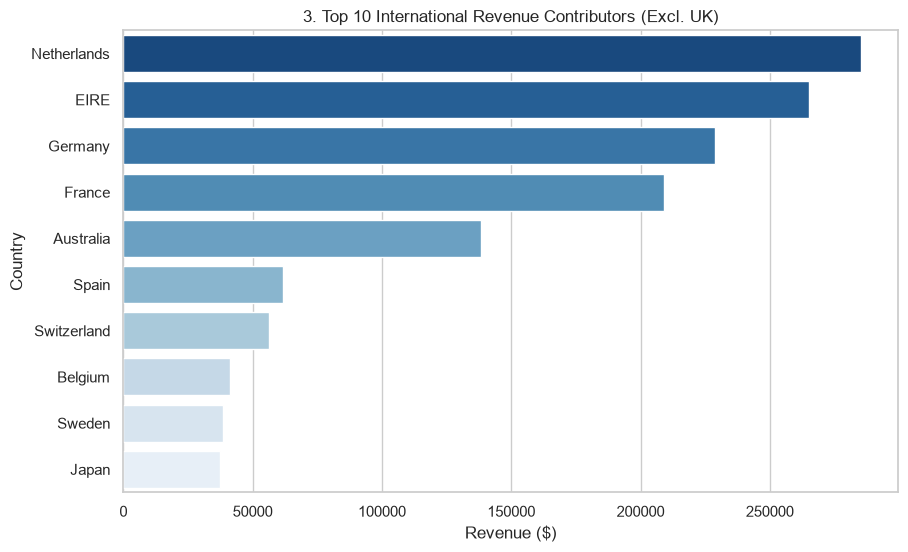

In [7]:
# 1. Top 10 Products by Total Revenue
top_rev = df_sales.groupby('Description')['TotalPrice'].sum().nlargest(10).reset_index()
plt.figure()
sns.barplot(data=top_rev, y='Description', x='TotalPrice', palette='viridis')
plt.title('1. Top 10 Products by Total Revenue Generated')
plt.xlabel('Revenue ($)')
plt.show()

# 2. Top 10 Products by Units Sold
top_qty = df_sales.groupby('Description')['Quantity'].sum().nlargest(10).reset_index()
plt.figure()
sns.barplot(data=top_qty, y='Description', x='Quantity', palette='magma')
plt.title('2. Top 10 Products by Total Quantity Sold')
plt.xlabel('Quantity Sold')
plt.show()

# 3. Top 10 Revenue Countries (Excl. United Kingdom)
top_intl = df_sales[df_sales['Country'] != 'United Kingdom'].groupby('Country')['TotalPrice'].sum().nlargest(10).reset_index()
plt.figure()
sns.barplot(data=top_intl, y='Country', x='TotalPrice', palette='Blues_r')
plt.title('3. Top 10 International Revenue Contributors (Excl. UK)')
plt.xlabel('Revenue ($)')
plt.show()

### D. 2 Count Plots 

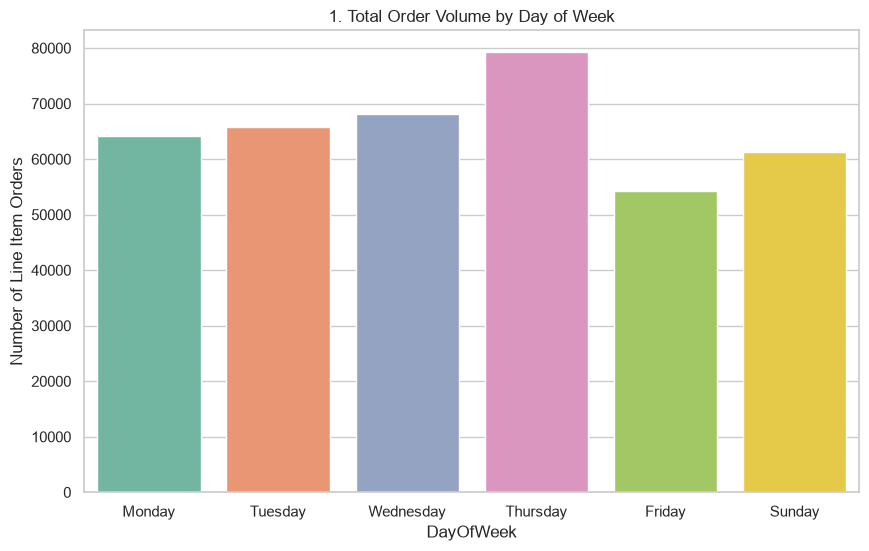

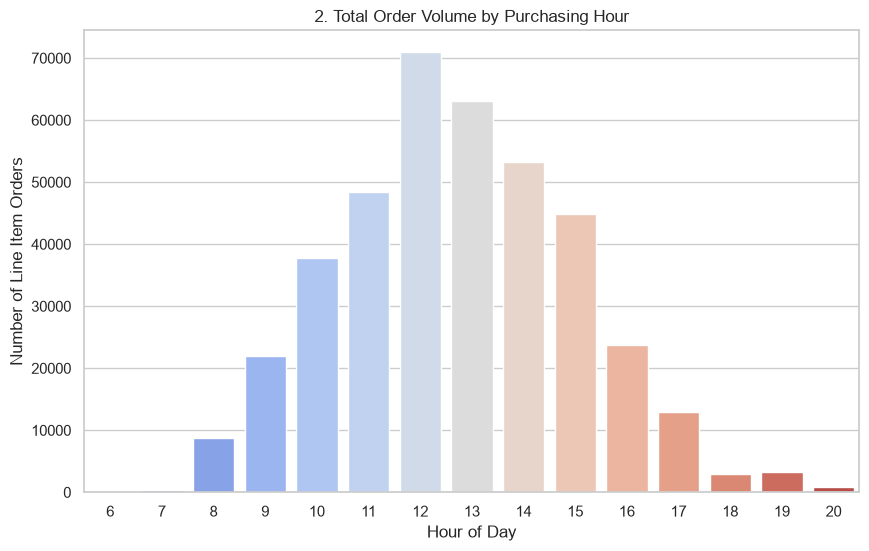

In [8]:
# 1. Count plot by Day of Week
plt.figure()
sns.countplot(data=df_sales, x='DayOfWeek', order=days_order, palette='Set2')
plt.title('1. Total Order Volume by Day of Week')
plt.ylabel('Number of Line Item Orders')
plt.show()

# 2. Count plot by Purchasing Hour
plt.figure()
sns.countplot(data=df_sales, x='Hour', palette='coolwarm')
plt.title('2. Total Order Volume by Purchasing Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Number of Line Item Orders')
plt.show()

### E. 2 Scatter Plots 

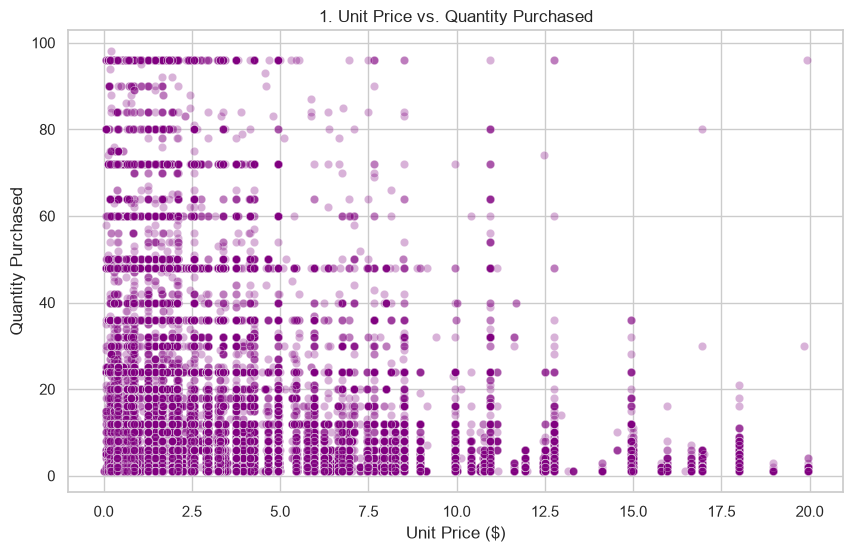

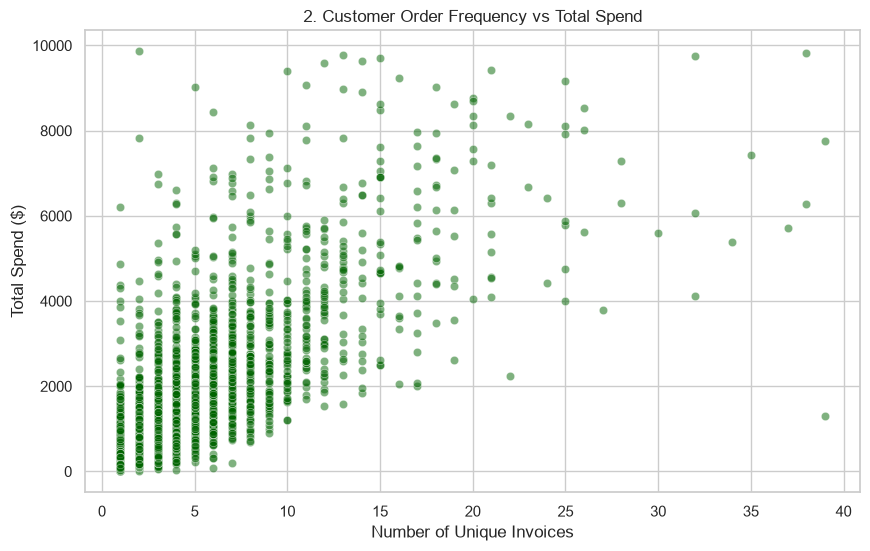

In [9]:
# 1. Unit Price vs Quantity Purchased
plt.figure()
sns.scatterplot(data=df_sales[(df_sales['Quantity'] < 100) & (df_sales['UnitPrice'] < 20)], x='UnitPrice', y='Quantity', alpha=0.3, color='purple')
plt.title('1. Unit Price vs. Quantity Purchased')
plt.xlabel('Unit Price ($)')
plt.ylabel('Quantity Purchased')
plt.show()

# 2. Customer-Level Aggregation: Total Spend vs Order Frequency
cust_df = df_sales.groupby('CustomerID').agg(TotalSpend=('TotalPrice', 'sum'), OrderCount=('InvoiceNo', 'nunique')).reset_index()
plt.figure()
sns.scatterplot(data=cust_df[(cust_df['TotalSpend'] < 10000) & (cust_df['OrderCount'] < 50)], x='OrderCount', y='TotalSpend', alpha=0.5, color='darkgreen')
plt.title('2. Customer Order Frequency vs Total Spend')
plt.xlabel('Number of Unique Invoices')
plt.ylabel('Total Spend ($)')
plt.show()

### F. Correlation Heatmap & Time-Series Chart 

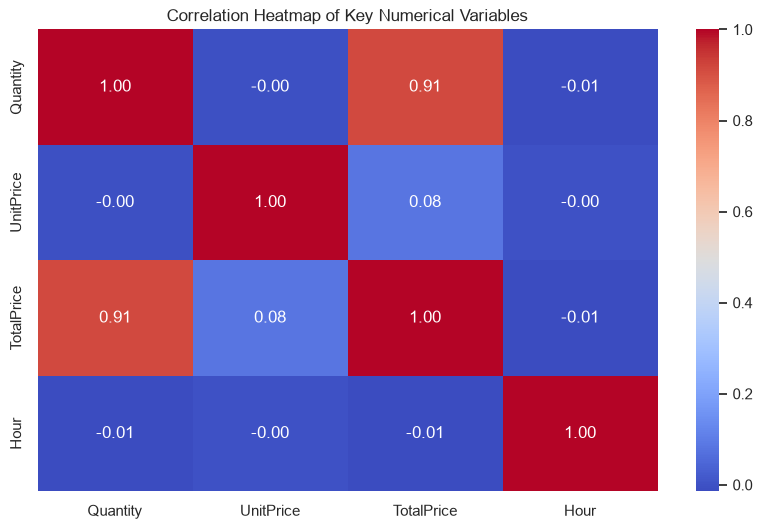

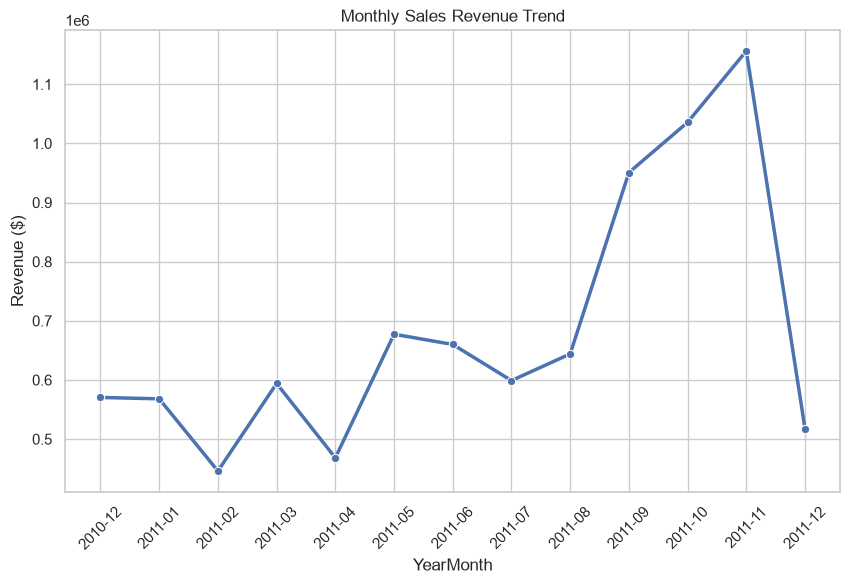

In [10]:
# Correlation Heatmap
plt.figure()
corr_matrix = df_sales[['Quantity', 'UnitPrice', 'TotalPrice', 'Hour']].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap of Key Numerical Variables')
plt.show()

# Time-Series Chart: Monthly Revenue Trend
monthly_rev = df_sales.groupby('YearMonth')['TotalPrice'].sum().reset_index()
monthly_rev['YearMonth'] = monthly_rev['YearMonth'].astype(str)

plt.figure()
sns.lineplot(data=monthly_rev, x='YearMonth', y='TotalPrice', marker='o', linewidth=2.5, color='b')
plt.title('Monthly Sales Revenue Trend')
plt.xticks(rotation=45)
plt.ylabel('Revenue ($)')
plt.show()

### G. Additional Custom Visualizations (2 nos.)

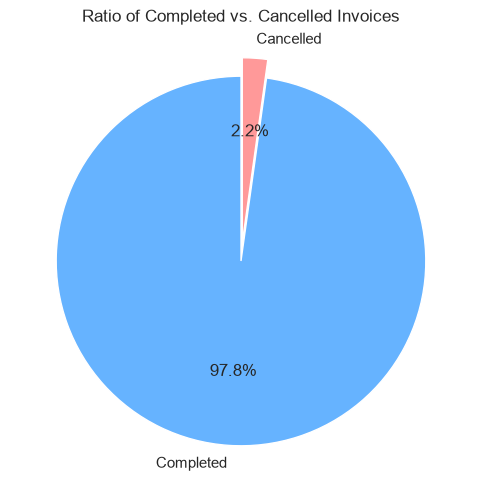

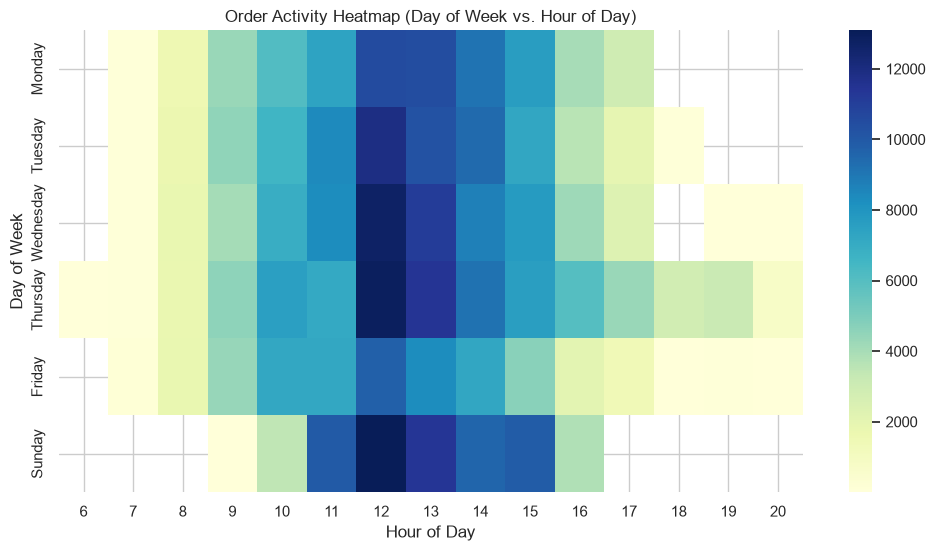

In [11]:
# 1. Cancellation Proportion Donut Chart
cancel_counts = df_clean['IsCancelled'].value_counts()
plt.figure()
plt.pie(cancel_counts, labels=['Completed', 'Cancelled'], autopct='%1.1f%%', startangle=90, colors=['#66b3ff', '#ff9999'], explode=(0, 0.1))
plt.title('Ratio of Completed vs. Cancelled Invoices')
plt.show()

# 2. Hourly Order Heatmap by Day of Week
heatmap_data = df_sales.pivot_table(index='DayOfWeek', columns='Hour', values='InvoiceNo', aggfunc='count').reindex(days_order)
plt.figure(figsize=(12, 6))
sns.heatmap(heatmap_data, cmap='YlGnBu', annot=False)
plt.title('Order Activity Heatmap (Day of Week vs. Hour of Day)')
plt.xlabel('Hour of Day')
plt.ylabel('Day of Week')
plt.show()

## 5. Summary of Findings & Business Recommendations

### Key Insights:
1. **Peak Operating Hours:** Transaction counts peak between 10 AM and 3 PM. Thursday records the highest activity overall.
2. **Geographical Concentration:** The domestic UK market dominates total revenue. The largest international markets are the Netherlands, EIRE (Ireland), and Germany.
3. **Order Cancellations:** Approximately 2% to 4% of total transaction records represent cancellations, which require streamlined returns workflow management.

### Business Recommendations:
- **Targeted Promotions:** Schedule targeted marketing emails around 10:00 AM on weekdays to align with maximum user activity.
- **Inventory Management:** Prioritize warehouse allocations for top 10 revenue-generating stock items to prevent out-of-stock events during quarterly sales spikes.

# 6. Answers to Investigation Questions

**1. Which products generate the highest sales?**

"PAPER CRAFT, LITTLE BIRDIE" and "REGENCY CAKESTAND 3 TIER" generated the highest total revenue out of all inventory items.

**2. Which countries contribute the most revenue?**

While the United Kingdom completely dominates total sales, the top international revenue contributors are the Netherlands, EIRE, Germany, and France.

**3. What are the monthly/weekly sales trends?**

Monthly revenue trends upward throughout the year, peaking drastically in November for the holiday season before dropping in December. Weekly, Thursday sees the highest order volume, with purchasing activity typically peaking around 12:00 PM (Noon).

**4. Which products have the highest quantity sold?**

"PAPER CRAFT, LITTLE BIRDIE" and the "MEDIUM CERAMIC TOP STORAGE JAR" boast the highest total physical quantity sold.

**5. What is the average order value?**

The distribution of total price per line item shows that the vast majority of orders fall under $20, heavily clustered at the lowest end of the distribution curve.

**6. Who are the most valuable customers?**

The most valuable customers are a distinct cohort of high-frequency "wholesale" buyers who generate 15+ unique invoices and spend significantly more (up to $10,000+) than standard retail users.

**7. Are there unusual transactions or outliers?**

Yes, there are extreme outliers in the total spend distribution across countries, as well as massive single-order quantities (thousands of units) that skew the distributions far outside the standard interquartile ranges.

**8. What percentage of transactions are cancelled?**

Cancelled transactions make up exactly 2.2% of the total recorded invoices, leaving a 97.8% completion rate.

**9. Which products show increasing or declining demand?**

Overall inventory demand scales aggressively leading into Q4, reaching its highest peak in November (indicating strong demand for holiday and gifting items) before sharply declining into December.

**10. Is there a relationship between product price and quantity purchased?**

Yes, there is a distinct negative relationship. The scatter plot reveals that high-volume purchases (bulk orders of 60 to 100+ units) are exclusively restricted to lower-cost items priced under $5.00.